# Câu 4: Khảo sát sự liên quan giữa Trình độ học vấn (education), Khoản vay (loan) với khả năng đăng ký, phân biệt theo tình trạng hôn nhân

Phần 1 – Bài 2 (trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing giống phần hướng dẫn.

Dữ liệu dùng: `bank-full.csv` (45.211 khách hàng, 16 thuộc tính + thuộc tính quyết định `y` – có đăng ký gửi tiền có kỳ hạn hay không).

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_csv(DATA + 'bank-full.csv', sep=';')
df['y_num'] = (df['y'] == 'yes').astype(int)   # dùng để tính tỷ lệ đăng ký

---
## Thực hiện yêu cầu

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


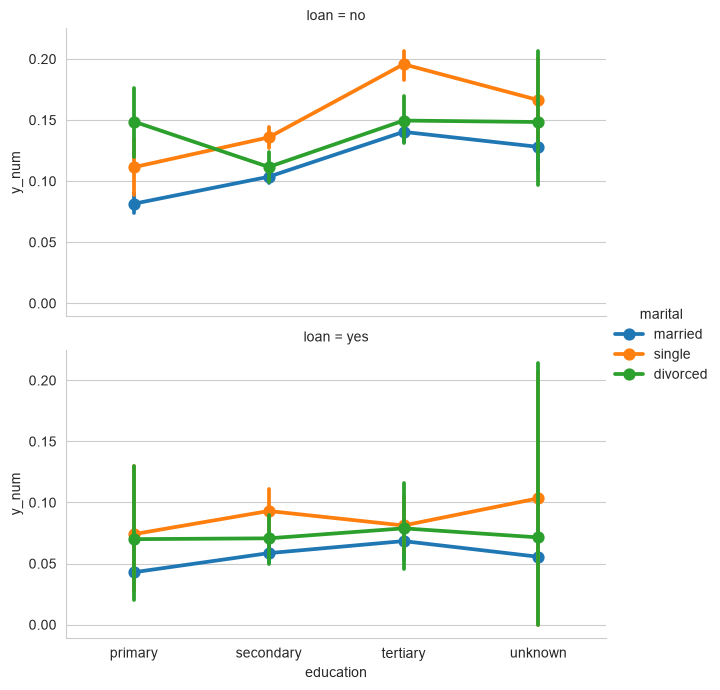

In [4]:
print(SV)
sns.catplot(data=df, x='education', y='y_num', hue='marital', row='loan', kind='point',
            order=['primary', 'secondary', 'tertiary', 'unknown'], height=3.5, aspect=1.8)
plt.show()

In [5]:
pd.crosstab([df['loan'], df['education']], df['marital'], values=df['y_num'], aggfunc='mean').round(3)

marital         divorced  married  single
loan education                           
no   primary       0.149    0.081   0.111
     secondary     0.112    0.104   0.136
     tertiary      0.150    0.140   0.196
     unknown       0.148    0.128   0.166
yes  primary       0.070    0.043   0.074
     secondary     0.071    0.059   0.093
     tertiary      0.079    0.068   0.081
     unknown       0.071    0.056   0.103

Xét riêng nghề nghiệp (job) với khả năng đăng ký:

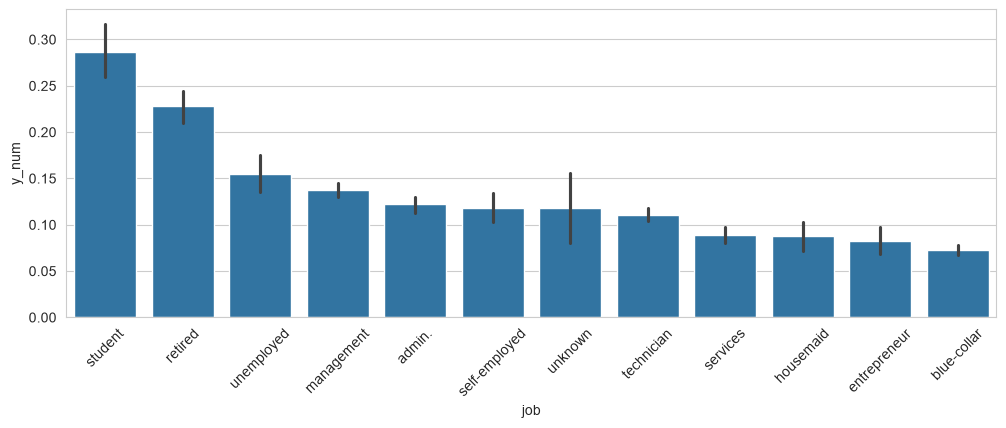

In [6]:
order = df.groupby('job')['y_num'].mean().sort_values(ascending=False).index
plt.figure(figsize=(12, 4))
sns.barplot(x='job', y='y_num', data=df, order=order)
plt.xticks(rotation=45)
plt.show()

**Nhận xét:**

- Học vấn càng cao thì tỷ lệ đăng ký càng cao: tertiary (đại học) cao nhất ở hầu hết các nhóm, primary thấp nhất.
- Khách đang có khoản vay cá nhân (`loan = yes`) đăng ký ít hơn hẳn, chỉ khoảng một nửa so với khách không vay (≈4–10% so với ≈8–20%), vì họ ít tiền nhàn rỗi.
- Ở mọi mức học vấn, khách độc thân có tỷ lệ đăng ký cao nhất; cao nhất là độc thân, học đại học, không vay (≈19,6%).
- Theo nghề: sinh viên (≈29%) và người nghỉ hưu (≈23%) đăng ký nhiều nhất; blue-collar, entrepreneur, housemaid đăng ký ít nhất (≈7–9%).